# Parte 2 — Entrenamiento y comparación de modelos de reconocimiento facial

Compara **dos enfoques** sobre el mismo conjunto de test y con las mismas métricas:

| | Modelo A — CNN custom | Modelo B — Preentrenado |
| --- | --- | --- |
| Qué es | ResNet liviana entrenada por el grupo con el dataset de la Parte 1 | InsightFace / ArcFace (`w600k_r50`) |
| Cómo se usa | Se entrena aquí y se exporta a ONNX | Extractor de embeddings, sin reentrenar |





## Equipo
- Alumno 1 : Uriel Duvia
- Alumno 2 : Laureano Diez

## Índice

**Setup**

1. [Ideas clave](#key-ideas)
2. [Instalar paquetes, repositorio y modelos](#setup)
3. [Imports y configuración](#imports)

**Datos**

4. [Splits y carga de imágenes](#data)

**Modelo A — CNN custom**

5. [Arquitectura](#arch)
6. [Dataset, augmentation y consistencia con el backend](#dataset)
7. [Entrenamiento y experimentos](#train)
8. [Exportación a ONNX](#export)

**Evaluación (A vs B)**

9. [Embeddings de ambos modelos](#embeddings)
10. [Verificación y calibración del umbral](#verification)
11. [Identificación open-set](#identification)
12. [Clustering de embeddings](#clustering)
13. [Análisis de errores](#errors)
14. [Costo computacional](#cost)

**Cierre**

15. [Tabla comparativa y elección final](#final)
16. [Conclusiones](#takeaways)

<a name='key-ideas'></a>
## Ideas clave

- **El objetivo no es clasificar** las identidades de entrenamiento, sino generar **embeddings** donde una misma persona quede cerca y personas distintas lejos. Así la app reconoce personas registradas *después* del entrenamiento.
- **Mismo preprocesamiento que el backend.** El entrenamiento usa `(x - 127.5) / 127.5` en RGB, igual que `lib.face_pipeline.preprocess_aligned_face`. La sección 6 lo verifica con un test numérico.
- **Se evalúa lo que se despliega.** Los embeddings del Modelo A se calculan con el **ONNX exportado** y la misma función que usa la app, no con el modelo de PyTorch.
- **Dos escenarios, tres roles para los datos.** `train`/`val` (closed-set) entrenan la CNN; `val_open` elige el mejor checkpoint y **calibra el umbral**; `test_open` (identidades nunca vistas) se usa **solo** para reportar. Nada de lo reportado se calibró en el mismo conjunto.
- **Mismas métricas y mismo protocolo** para A y B: verificación (ROC, AUC, EER, TAR@FAR), identificación open-set, clustering, errores y costo.

<a name='setup'></a>
## Instalar paquetes, repositorio y modelos

Como en la Parte 1: en Colab se instala lo que falta; en local se usa el `.venv` del repo. El repo se clona para poder importar `src/lib/` (pipeline, CNN, evaluación).

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip install -q insightface==0.7.3 onnxruntime onnx albumentations
else:
    # Local: instalar desde la terminal con el .venv activo (uv pip install -r requirements.txt).
    print("Entorno local: las dependencias se instalan desde la terminal.")

Entorno local: las dependencias se instalan desde la terminal.


In [2]:
import os

REPO_URL = "https://github.com/laureanodiez/tuia-face-recognition-app.git"
REPO_DIR = "tuia-face-recognition-app"

if not os.path.isfile("src/lib/face_pipeline.py"):
    if not os.path.isdir(REPO_DIR) and os.path.basename(os.getcwd()) != REPO_DIR:
        !git clone -q $REPO_URL
    if os.path.basename(os.getcwd()) != REPO_DIR:
        %cd $REPO_DIR

print("Working directory:", os.getcwd())

Working directory: c:\Users\U\Documents\python_proyectos\Python Proy\tuia-face-recognition-app


In [3]:
import urllib.request
import zipfile

os.makedirs("models", exist_ok=True)
NEEDED = ["w600k_r50.onnx"]   # reconocedor ArcFace ResNet-50 de InsightFace (Modelo B)

if not all(os.path.isfile(f"models/{n}") for n in NEEDED):
    url = "https://github.com/deepinsight/insightface/releases/download/v0.7/buffalo_l.zip"
    urllib.request.urlretrieve(url, "models/buffalo_l.zip")
    with zipfile.ZipFile("models/buffalo_l.zip") as z:
        for n in NEEDED:
            z.extract(n, "models")
    os.remove("models/buffalo_l.zip")

print({n: os.path.isfile(f"models/{n}") for n in NEEDED})

{'w600k_r50.onnx': True}


<a name='imports'></a>
## Imports y configuración

Todos los hiperparámetros y parámetros de evaluación están **juntos en una celda**.

In [4]:
import json
import random
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnx
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

sys.path.insert(0, "src")
from lib import evaluation as ev
from lib import face_pipeline as fp
from lib.augmentations import build_train_augmentation
from lib.models.custom_cnn import ArcMarginProduct, FaceEmbeddingNet

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE, "| torch", torch.__version__)

# --- Datos (salidas de 1-pre-processing.ipynb) ---
SPLITS_DIR = Path("data/splits")
FACE_SIZE = 112
EMB_DIM = 512               # debe coincidir con EMBEDDING_DIM del .env

# --- Entrenamiento del Modelo A ---
BATCH_SIZE = 64
EPOCHS = 20
PATIENCE = 5                # early stopping sobre el EER en val_open
LR, WEIGHT_DECAY = 1e-3, 5e-4
NUM_WORKERS = 0             # 0 evita problemas de multiprocessing en Windows/notebooks
CKPT_DIR = Path("models/checkpoints")
ONNX_PATH = Path("models/custom_cnn.onnx")
EXPERIMENTS = [
    dict(name="A1_softmax_gap",     m=0.0, pool="gap"),      # clasificación + embedding (margen 0)
    dict(name="A2_arcface_gap",     m=0.3, pool="gap"),      # margen angular ArcFace
    dict(name="A3_arcface_flatten", m=0.3, pool="flatten"),  # ¿ayuda conservar la posición espacial?
]

# --- Evaluación ---
N_PAIRS = 10000             # pares positivos y negativos (cada uno) para verificación
N_PAIRS_EPOCH = 3000        # pares usados para el EER por época (val_open)
FAR_TARGETS = (1e-2, 1e-3)
K_GALLERY = 3               # imágenes registradas por identidad en la galería (imita /insert)
N_REPEATS = 5               # repeticiones de la identificación con distintas galerías

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
CKPT_DIR.mkdir(parents=True, exist_ok=True)

c:\Users\U\Documents\python_proyectos\Python Proy\tuia-face-recognition-app\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cpu | torch 2.11.0+cpu


<a name='data'></a>
## Splits y carga de imágenes

Leemos `data/splits/splits.csv`, generado por la notebook 1, y cargamos **todos los recortes alineados 112 × 112 en memoria** (RGB, `uint8`). El dataset entero ocupa unos 400 MB, y entrenar sin releer JPGs en cada época es mucho más rápido.

| Split | Para qué se usa acá |
| --- | --- |
| `train` | entrenar la CNN (identidades conocidas) |
| `val` | loss y accuracy de validación (mismas identidades que train) |
| `val_open` | elegir el mejor checkpoint (EER) y **calibrar el umbral** |
| `test` | no se usa para el modelo final; queda como control closed-set |
| `test_open` | **solo reporte final**: identidades que ningún modelo vio |



In [5]:
# Ejemplo para Colab (descomentar y adaptar la ruta):
# from google.colab import drive; drive.mount("/content/drive")
# !cp -r /content/drive/MyDrive/tp_facial/data ./data

if not (SPLITS_DIR / "splits.csv").exists():
    raise FileNotFoundError("Falta data/splits/splits.csv: ejecutar primero 1-pre-processing.ipynb")

splits = pd.read_csv(SPLITS_DIR / "splits.csv")
for col in ("path", "aligned_path"):      # el CSV puede traer rutas con "\\" si se generó en Windows
    splits[col] = splits[col].str.replace("\\", "/", regex=False)

summary = splits.groupby("split").agg(identidades=("identity", "nunique"), imagenes=("path", "count"))
display(summary.reindex(["train", "val", "test", "val_open", "test_open"]))

,identidades,imagenes
split,,
train,74,4977
val,74,1066
test,74,1068
val_open,15,1426
test_open,16,1551


In [6]:
def load_rgb(paths):
    out = np.empty((len(paths), FACE_SIZE, FACE_SIZE, 3), dtype=np.uint8)
    for k, p in enumerate(tqdm(paths)):
        img = cv2.imread(p)
        if img is None:
            raise FileNotFoundError(p)
        if img.shape[:2] != (FACE_SIZE, FACE_SIZE):
            img = cv2.resize(img, (FACE_SIZE, FACE_SIZE), interpolation=cv2.INTER_AREA)
        out[k] = img[:, :, ::-1]          # BGR -> RGB
    return out

IMGS = load_rgb(splits.aligned_path.tolist())        # (N, 112, 112, 3) RGB uint8, mismo orden que splits
print("Imágenes en memoria:", IMGS.shape, f"| {IMGS.nbytes / 1e6:.0f} MB")

# Índices por split y mapeo de etiquetas para el entrenamiento (closed-set: solo las identidades de train).
idx_of = {s: splits.index[splits.split == s].to_numpy() for s in splits.split.unique()}
train_ids = sorted(splits.loc[idx_of["train"], "identity"].unique())
cls_of = {name: i for i, name in enumerate(train_ids)}
y_train = splits.loc[idx_of["train"], "identity"].map(cls_of).to_numpy()
y_val = splits.loc[idx_of["val"], "identity"].map(cls_of).to_numpy()
label_to_name = dict(zip(splits.label, splits.identity))
print("Clases de entrenamiento:", len(train_ids))

100%|██████████| 10088/10088 [00:08<00:00, 1192.21it/s]

Imágenes en memoria: (10088, 112, 112, 3) | 380 MB
Clases de entrenamiento: 74


<a name='arch'></a>
## Modelo A — Arquitectura

**ResNet liviana** (`src/lib/models/custom_cnn.py`), pensada para un dataset chico (~5.000 imágenes de entrenamiento):

```
RGB 112×112 → Stem conv 3×3 s2 (32) → 4 etapas residuales (32, 64, 128, 256; stride 2 desde la 2ª)
            → pooling → Dropout(0.3) → Linear(→512) → BatchNorm1d → L2-normalize
```

| Decisión | Justificación |
| --- | --- |
| **Bloques residuales** | Facilitan el flujo del gradiente y permiten una red profunda con pocos parámetros. |
| **BatchNorm + PReLU** | BatchNorm estabiliza el entrenamiento con lotes chicos; PReLU es la activación usada en ArcFace y suele rendir mejor que ReLU en rostros. |
| **Global average pooling** (por defecto) | Muy pocos parámetros (~1,4 M) y menos riesgo de overfitting con pocos datos. El experimento A3 lo compara con aplanar el mapa 7×7 (~7,7 M). |
| **Dropout 0.3** | Regulariza la capa de embedding, la más grande de la red. |
| **BatchNorm1d + normalización L2 al final** | La salida es un vector unitario: el coseno equivale a un producto punto y coincide con lo que espera `FaceService`. |
| **Dimensión 512** | Igual que ArcFace: no hay que cambiar `EMBEDDING_DIM` en el `.env` ni recrear la tabla de pgvector. |

**Cabeza de entrenamiento (se descarta al exportar):** clasificador por coseno con margen angular (`ArcMarginProduct`).
Con `m = 0` equivale a *softmax* sobre cosenos (enfoque "clasificación + embedding"); con `m > 0` es **ArcFace** (metric learning), que obliga a las clases a separarse por un margen angular.

In [7]:
for pool in ("gap", "flatten"):
    m = FaceEmbeddingNet(EMB_DIM, pool=pool)
    n_params = sum(p.numel() for p in m.parameters())
    print(f"pool={pool:8s} parámetros: {n_params / 1e6:.2f} M")

print()
print(FaceEmbeddingNet(EMB_DIM, pool="gap"))

pool=gap      parámetros: 1.36 M
pool=flatten  parámetros: 7.65 M

FaceEmbeddingNet(
  (stem): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): PReLU(num_parameters=32)
  )
  (stages): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act1): PReLU(num_parameters=32)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act2): PReLU(num_parameters=32)
      (shortcut): Identity()
    )
    (1): BasicBlock(
      (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-

<a name='dataset'></a>
## Dataset, augmentation y consistencia con el backend

- La **augmentation** (`lib/augmentations.py`) es la misma de la sección 15 de la notebook 1 y se aplica **solo a train**.
- Después se normaliza con `(x - 127.5) / 127.5` en RGB y se pasa a `CHW`, **igual que** `fp.preprocess_aligned_face`, que usa el backend.

La última celda verifica numéricamente que ambos caminos dan exactamente el mismo tensor.

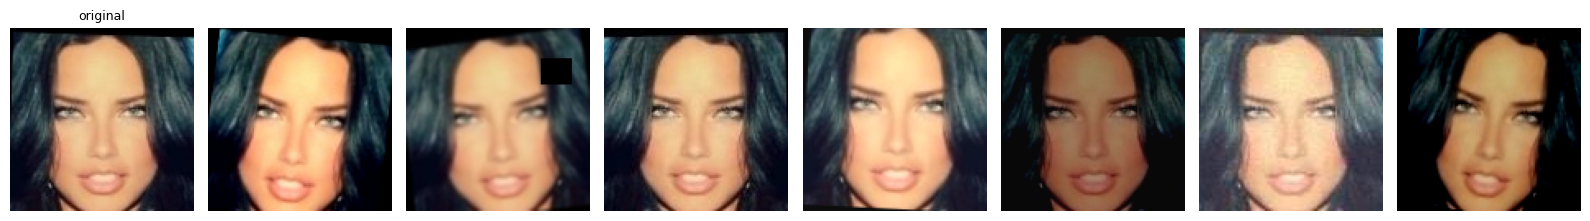

Diferencia máxima dataset vs backend: 0.0


In [8]:
AUG = build_train_augmentation()


class FaceDataset(Dataset):
    # imgs: (N, 112, 112, 3) RGB uint8; labels: enteros; augment: None en validación/test.
    def __init__(self, imgs, labels, augment=None):
        self.imgs, self.labels, self.augment = imgs, np.asarray(labels), augment

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        img = self.imgs[i]
        if self.augment is not None:
            img = self.augment(image=img)["image"]
        x = (img.astype(np.float32) - fp.ARCFACE_MEAN) / fp.ARCFACE_STD
        return torch.from_numpy(x.transpose(2, 0, 1)), int(self.labels[i])


# Ejemplo visual: una imagen de train con 7 augmentations.
example = IMGS[idx_of["train"][0]]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(example); axes[0].set_title("original", fontsize=9)
for ax in axes[1:]:
    ax.imshow(AUG(image=example)["image"])
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.show()

# Test de consistencia con el backend: dataset (sin augmentation) vs fp.preprocess_aligned_face.
x_ds, _ = FaceDataset(IMGS[:1], [0])[0]
x_fp = fp.preprocess_aligned_face(IMGS[0][:, :, ::-1])[0]     # el backend entrega BGR
diff = float(np.abs(x_ds.numpy() - x_fp).max())
print("Diferencia máxima dataset vs backend:", diff)
assert diff < 1e-6, "El preprocesamiento de entrenamiento NO coincide con el del backend"

<a name='train'></a>
## Entrenamiento y experimentos

- **Pérdida:** entropía cruzada sobre los logits de la cabeza (con margen si `m > 0`).
- **Optimizador:** AdamW (`lr = 1e-3`, `weight_decay = 5e-4`) con *scheduler* **OneCycle**.
- **Early stopping y checkpoint:** en cada época se mide el **EER de verificación en `val_open`** (identidades que el modelo no vio) y se guarda el mejor. Es la métrica más cercana al uso real de la app. La *loss* y el *accuracy* de `val` (closed-set) se registran para diagnosticar overfitting.
- **Experimentos:** tres configuraciones que responden preguntas concretas: ¿ayuda el margen angular (A1 vs A2)? ¿ayuda conservar la posición espacial (A2 vs A3)?

> **Tiempo:** en CPU cada época de ~5.000 imágenes puede tardar 1–2 minutos y son 3 experimentos. Con GPU (Colab) son segundos por época. Si no hay GPU, reducir `EPOCHS` o dejar solo un experimento.

In [9]:
val_open_idx, test_open_idx = idx_of["val_open"], idx_of["test_open"]
lab_val = splits.loc[val_open_idx, "label"].to_numpy()
lab_test = splits.loc[test_open_idx, "label"].to_numpy()
PAIRS_EPOCH = ev.make_pairs(lab_val, N_PAIRS_EPOCH, SEED)       # pares fijos para comparar épocas


@torch.no_grad()
def embed_array(model, imgs, bs=256):
    # Embeddings de un array RGB uint8 con un modelo de PyTorch (solo para monitorear el entrenamiento).
    model.eval()
    out = []
    for i in range(0, len(imgs), bs):
        x = (imgs[i:i + bs].astype(np.float32) - fp.ARCFACE_MEAN) / fp.ARCFACE_STD
        out.append(model(torch.from_numpy(x.transpose(0, 3, 1, 2)).to(DEVICE)).cpu().numpy())
    return np.concatenate(out)


@torch.no_grad()
def eval_closed(model, head, loader):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = head.logits(model(x))                       # sin margen
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return loss_sum / n, correct / n


def fit(name, m=0.3, pool="gap", s=30.0, dropout=0.3, lr=LR, wd=WEIGHT_DECAY, epochs=EPOCHS, use_aug=True):
    set_seed(SEED)
    model = FaceEmbeddingNet(EMB_DIM, dropout=dropout, pool=pool).to(DEVICE)
    head = ArcMarginProduct(EMB_DIM, len(train_ids), s=s, m=m).to(DEVICE)
    train_loader = DataLoader(
        FaceDataset(IMGS[idx_of["train"]], y_train, AUG if use_aug else None),
        batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS)
    val_loader = DataLoader(FaceDataset(IMGS[idx_of["val"]], y_val), batch_size=256, num_workers=NUM_WORKERS)

    opt = torch.optim.AdamW(list(model.parameters()) + list(head.parameters()), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(train_loader), pct_start=0.15)

    history, best, bad, t0 = [], {"eer": 1.0}, 0, time.time()
    for epoch in range(1, epochs + 1):
        model.train(); head.train()
        loss_sum, correct, n = 0.0, 0, 0
        for x, y in tqdm(train_loader, desc=f"{name} ep{epoch}", leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            emb = model(x)
            loss = F.cross_entropy(head(emb, y), y)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            loss_sum += loss.item() * len(y); n += len(y)
            correct += (head.logits(emb.detach()).argmax(1) == y).sum().item()
        val_loss, val_acc = eval_closed(model, head, val_loader)
        emb_vo = embed_array(model, IMGS[val_open_idx])
        eer = ev.verification_metrics(ev.pair_scores(emb_vo, *PAIRS_EPOCH[:2]), PAIRS_EPOCH[2])["eer"]
        history.append(dict(epoch=epoch, train_loss=loss_sum / n, train_acc=correct / n,
                            val_loss=val_loss, val_acc=val_acc, val_open_eer=eer))
        print(f"[{name}] ep{epoch:02d} train_loss={loss_sum / n:.3f} acc={correct / n:.3f} | "
              f"val_loss={val_loss:.3f} acc={val_acc:.3f} | val_open EER={eer:.4f}")
        if eer < best["eer"]:
            best = {"eer": eer, "epoch": epoch}
            torch.save(model.state_dict(), CKPT_DIR / f"{name}.pth")
            bad = 0
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"Early stopping en la época {epoch} (mejor: {best['epoch']})")
                break
    best["minutes"] = (time.time() - t0) / 60
    best["params_M"] = sum(p.numel() for p in model.parameters()) / 1e6
    return pd.DataFrame(history), best

In [10]:
RUNS = {}
for cfg in EXPERIMENTS:
    cfg = dict(cfg)
    name = cfg.pop("name")
    hist, best = fit(name, **cfg)
    RUNS[name] = dict(cfg=cfg, history=hist, best=best)

# Tabla de experimentos
exp_table = pd.DataFrame([
    dict(experimento=n, margen_m=r["cfg"]["m"], pooling=r["cfg"]["pool"],
         parametros_M=round(r["best"]["params_M"], 2), mejor_epoca=r["best"]["epoch"],
         val_open_EER=round(r["best"]["eer"], 4),
         val_acc_en_mejor=round(float(r["history"].loc[r["history"].epoch == r["best"]["epoch"], "val_acc"].iloc[0]), 3),
         minutos=round(r["best"]["minutes"], 1))
    for n, r in RUNS.items()
]).sort_values("val_open_EER")
display(exp_table)
BEST_NAME = exp_table.iloc[0].experimento
print("Mejor experimento (menor EER en val_open):", BEST_NAME)

[A1_softmax_gap] ep01 train_loss=4.827 acc=0.019 | val_loss=4.314 acc=0.053 | val_open EER=0.4617


[A1_softmax_gap] ep02 train_loss=4.501 acc=0.032 | val_loss=4.315 acc=0.044 | val_open EER=0.4585


[A1_softmax_gap] ep03 train_loss=4.387 acc=0.043 | val_loss=4.198 acc=0.054 | val_open EER=0.4537


[A1_softmax_gap] ep04 train_loss=4.212 acc=0.058 | val_loss=3.857 acc=0.088 | val_open EER=0.4545


[A1_softmax_gap] ep05 train_loss=4.039 acc=0.077 | val_loss=3.797 acc=0.131 | val_open EER=0.4318


[A1_softmax_gap] ep06 train_loss=3.893 acc=0.095 | val_loss=3.569 acc=0.125 | val_open EER=0.4357


... (52 outputs left out)

[A3_arcface_flatten] ep19 train_loss=3.687 acc=0.893 | val_loss=0.534 acc=0.871 | val_open EER=0.2380


[A3_arcface_flatten] ep20 train_loss=3.634 acc=0.893 | val_loss=0.535 acc=0.872 | val_open EER=0.2347


,experimento,margen_m,pooling,parametros_M,mejor_epoca,val_open_EER,val_acc_en_mejor,minutos
2,A3_arcface_flatten,0.3,flatten,7.65,20,0.2347,0.872,34.2
1,A2_arcface_gap,0.3,gap,1.36,18,0.2717,0.577,31.9
0,A1_softmax_gap,0.0,gap,1.36,20,0.2818,0.572,31.7


Mejor experimento (menor EER en val_open): A3_arcface_flatten


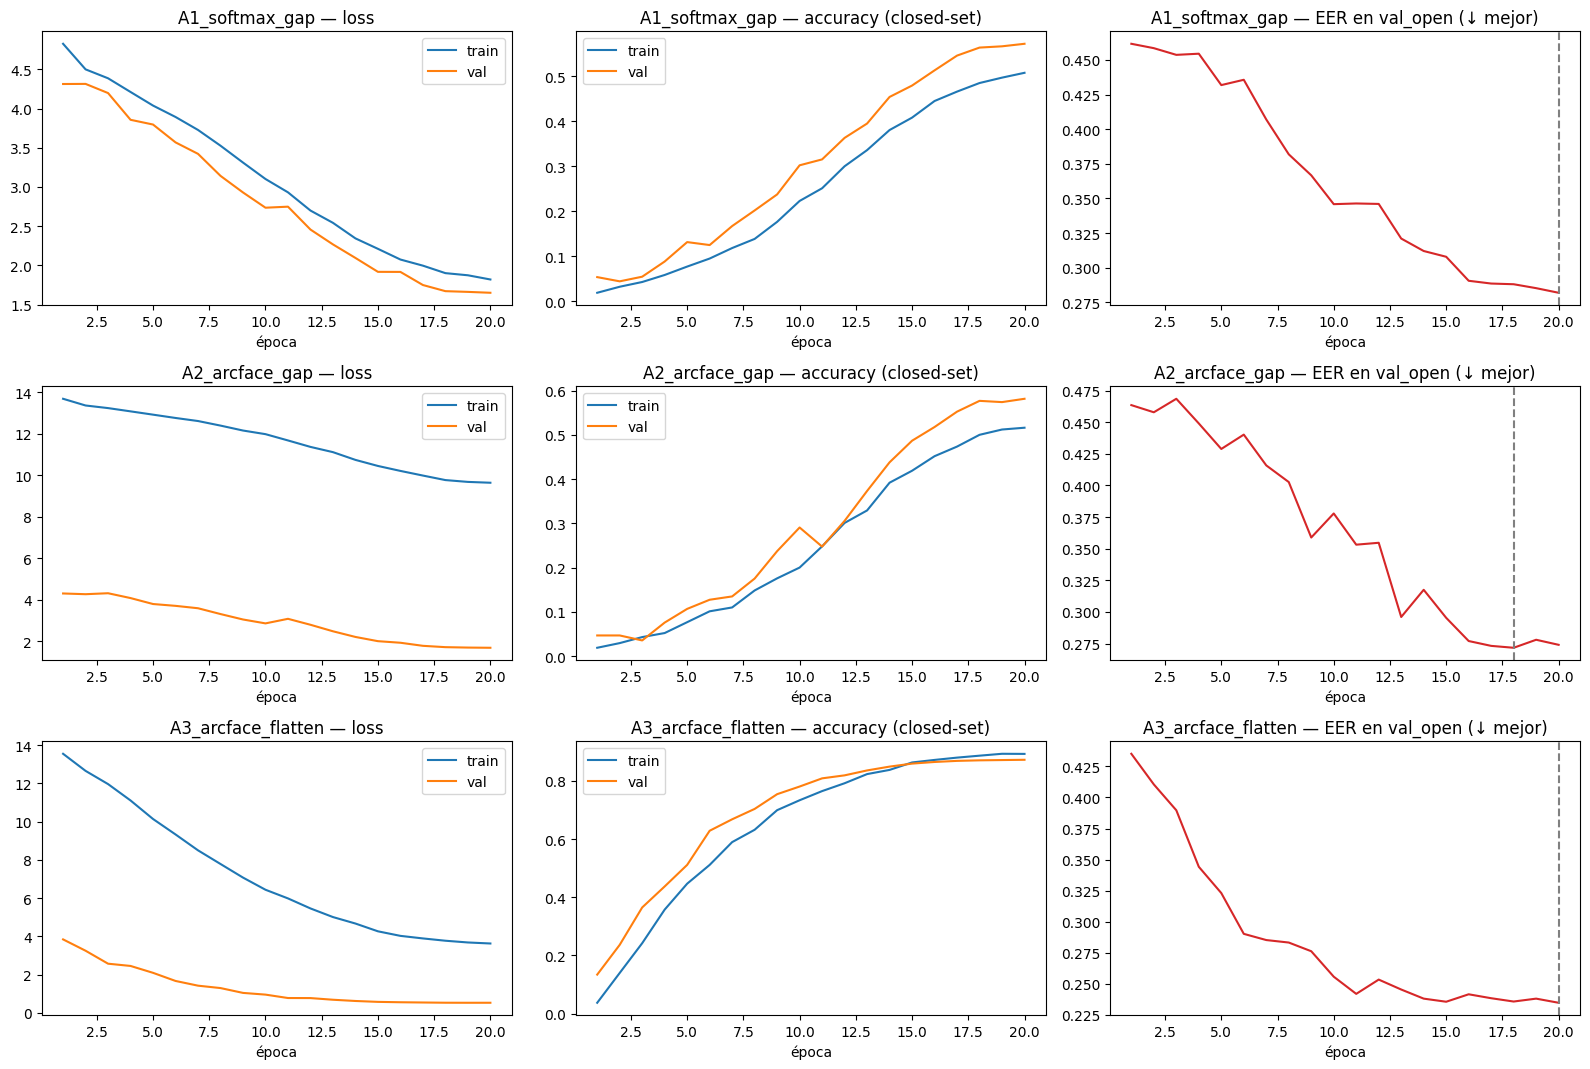

In [11]:
# Curvas de entrenamiento: loss, accuracy y EER de val_open para cada experimento.
fig, axes = plt.subplots(len(RUNS), 3, figsize=(16, 3.6 * len(RUNS)), squeeze=False)
for row, (n, r) in enumerate(RUNS.items()):
    h = r["history"]
    axes[row, 0].plot(h.epoch, h.train_loss, label="train"); axes[row, 0].plot(h.epoch, h.val_loss, label="val")
    axes[row, 0].set_title(f"{n} — loss"); axes[row, 0].legend()
    axes[row, 1].plot(h.epoch, h.train_acc, label="train"); axes[row, 1].plot(h.epoch, h.val_acc, label="val")
    axes[row, 1].set_title(f"{n} — accuracy (closed-set)"); axes[row, 1].legend()
    axes[row, 2].plot(h.epoch, h.val_open_eer, color="C3")
    axes[row, 2].axvline(r["best"]["epoch"], ls="--", color="gray")
    axes[row, 2].set_title(f"{n} — EER en val_open (↓ mejor)")
    for ax in axes[row]:
        ax.set_xlabel("época")
plt.tight_layout(); plt.show()


### Interpretación de las curvas de entrenamiento

Las curvas de entrenamiento muestran una disminución progresiva de la pérdida y un aumento de la accuracy, lo que indica que los modelos lograron aprender patrones presentes en las imágenes.

En A1, el aprendizaje fue más lento, alcanzando una accuracy de validación cercana al 58 %. Esto puede relacionarse con la capacidad limitada de la arquitectura y las dificultades propias de aprender representaciones faciales a partir de un dataset reducido.

A2 incorporó el margen angular y obtuvo una mejora moderada del EER de validación open-set, aunque sin un aumento importante de la accuracy closed-set.

En A3, la accuracy de entrenamiento alcanzó aproximadamente 89 % y la de validación 87,4 %. La diferencia entre ambas fue reducida al finalizar el entrenamiento, por lo que estas métricas no muestran una señal fuerte de sobreajuste en las identidades conocidas.

Sin embargo, la accuracy closed-set no es suficiente para evaluar la generalización del reconocimiento facial. El objetivo es distinguir personas que no participaron del entrenamiento.

Por ese motivo, se utilizó el EER sobre `val_open` como criterio principal para seleccionar el mejor checkpoint.

En A3, el EER disminuyó progresivamente hasta alcanzar 0,2283. Esto demuestra una mejora en la capacidad de verificación, aunque el error sigue siendo considerable.

Los experimentos estuvieron limitados a un máximo de 20 épocas. Por lo tanto, no puede descartarse que entrenamientos más largos u otros ajustes de hiperparámetros permitan mejorar los resultados.


In [12]:
best_cfg = RUNS[BEST_NAME]["cfg"]
model_A = FaceEmbeddingNet(EMB_DIM, pool=best_cfg["pool"])
model_A.load_state_dict(torch.load(CKPT_DIR / f"{BEST_NAME}.pth", map_location="cpu"))
model_A.eval()

dummy = torch.randn(1, 3, FACE_SIZE, FACE_SIZE)
export_kwargs = dict(input_names=["input"], output_names=["embedding"],
                     dynamic_axes={"input": {0: "batch"}, "embedding": {0: "batch"}}, opset_version=17)
try:
    torch.onnx.export(model_A, dummy, str(ONNX_PATH), dynamo=False, **export_kwargs)
except TypeError:          # versiones de torch sin el argumento `dynamo`
    torch.onnx.export(model_A, dummy, str(ONNX_PATH), **export_kwargs)

sess_A = fp.make_session(ONNX_PATH)
print("Entrada ONNX:", sess_A.get_inputs()[0].shape, "| lado leído del modelo:", fp.model_input_size(sess_A))

# Paridad PyTorch vs ONNX, pasando por el MISMO camino que usa el backend (fp.embed_onnx, entrada BGR).
check = np.random.RandomState(0).choice(len(IMGS), 20, replace=False)
e_onnx = np.stack([fp.embed_onnx(sess_A, IMGS[i][:, :, ::-1]) for i in check])
e_torch = embed_array(model_A.to(DEVICE), IMGS[check])
print("Diferencia máxima ONNX vs PyTorch:", float(np.abs(e_onnx - e_torch).max()))
assert np.abs(e_onnx - e_torch).max() < 1e-3
print("Modelo exportado:", ONNX_PATH, f"({ONNX_PATH.stat().st_size / 1e6:.1f} MB)")

C:\Users\U\AppData\Local\Temp\ipykernel_13416\3743383490.py:10: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model_A, dummy, str(ONNX_PATH), dynamo=False, **export_kwargs)


Entrada ONNX: ['batch', 3, 112, 112] | lado leído del modelo: 112
Diferencia máxima ONNX vs PyTorch: 1.1245720088481903e-07
Modelo exportado: models\custom_cnn.onnx (30.6 MB)


<a name='embeddings'></a>
## Embeddings de ambos modelos

Los dos modelos se evalúan **sobre embeddings**, con el mismo protocolo, en `val_open` (calibración) y `test_open` (reporte).

- **Modelo A:** embeddings del ONNX exportado, con `fp.embed_onnx` (el camino exacto del backend).
- **Modelo B:** los embeddings de `w600k_r50` que ya calculó la notebook 1 (`embeddings_buffalo_w600k_r50.npy`), verificados contra un recálculo de control. El modelo se usa **sin reentrenar**.

**Documentación del Modelo B:** detector **SCRFD** (`det_10g`) + reconocedor **ArcFace con backbone ResNet-50** (`w600k_r50`) del paquete `buffalo_l` de InsightFace. Entrenado con un dataset de reconocimiento facial a gran escala (WebFace600K, según la documentación de InsightFace; verificar las cifras exactas antes de citarlas). Produce embeddings de **512 dimensiones**. **Licencia: uso no comercial / investigación**, compatible con este TP académico.

In [13]:
sess_B = fp.make_session("models/w600k_r50.onnx")
emb_B_all = np.load(SPLITS_DIR / "embeddings_buffalo_w600k_r50.npy")
assert len(emb_B_all) == len(splits), "El .npy no coincide con splits.csv: volver a ejecutar la notebook 1"

# Control: recalcular algunos embeddings y comparar con los guardados.
chk = np.random.RandomState(1).choice(len(splits), 20, replace=False)
re = np.stack([fp.embed_onnx(sess_B, IMGS[i][:, :, ::-1]) for i in chk])
print("Diferencia máxima embeddings guardados vs recalculados:", float(np.abs(re - emb_B_all[chk]).max()))
assert np.abs(re - emb_B_all[chk]).max() < 1e-4


def embed_onnx_idx(session, idx):
    return np.stack([fp.embed_onnx(session, IMGS[i][:, :, ::-1]) for i in tqdm(idx)])


MODELS = {
    "A: CNN custom": {"val": embed_onnx_idx(sess_A, val_open_idx), "test": embed_onnx_idx(sess_A, test_open_idx)},
    "B: InsightFace w600k_r50": {"val": emb_B_all[val_open_idx], "test": emb_B_all[test_open_idx]},
}
for k, v in MODELS.items():
    print(k, {s: e.shape for s, e in v.items()})

Diferencia máxima embeddings guardados vs recalculados: 0.0


100%|██████████| 1551/1551 [00:07<00:00, 215.14it/s]

A: CNN custom {'val': (1426, 512), 'test': (1551, 512)}
B: InsightFace w600k_r50 {'val': (1426, 512), 'test': (1551, 512)}


<a name='verification'></a>
## Verificación y calibración del umbral

**¿Son la misma persona?** Se generan **pares balanceados** (10.000 positivos y 10.000 negativos) a partir de identidades nunca vistas, y se mide el coseno de cada par.


### Interpretación de la verificación facial

Se evaluó la capacidad de ambos modelos para determinar si dos imágenes corresponden a una misma persona.

Para ello, se utilizaron pares positivos y negativos de identidades no vistas y se calculó la similitud coseno entre sus embeddings.

La CNN propia obtuvo un AUC de 0,8746 y un EER de 0,2126. Estos resultados indican que aprendió características útiles para diferenciar identidades, aunque todavía existe un solapamiento importante entre las similitudes de personas iguales y diferentes.

InsightFace obtuvo un AUC redondeado de 1,0000 y un EER de 0,0017, mostrando una separación mucho más efectiva de las identidades en el conjunto evaluado.

La diferencia también se observa en TAR@FAR=1e-3:

- CNN propia: 0,1136.
- InsightFace: 0,9975.

Esto significa que, para una tasa objetivo de falsos positivos de 0,1 %, InsightFace logra aceptar una proporción mucho mayor de pares positivos.

### Calibración del umbral

Los umbrales fueron seleccionados utilizando exclusivamente el conjunto `val_open`, mediante el punto EER.

Se obtuvieron los siguientes valores:

- CNN propia: 0,1799.
- InsightFace: 0,2204.

Al aplicar estos umbrales sin modificarlos sobre `test_open`, se observaron:

| Modelo | FAR | FRR |
|---|---:|---:|
| CNN propia | 17,67 % | 25,16 % |
| InsightFace | 0,13 % | 0,24 % |

La CNN propia presenta una tasa de falsos positivos elevada, lo que representa un problema para un sistema que debe evitar confundir identidades.

Por el contrario, InsightFace consigue tasas de error considerablemente menores.

Por estos motivos, InsightFace resulta más adecuado para la aplicación final, especialmente cuando es importante evitar identificaciones incorrectas.


In [14]:
pairs_val = ev.make_pairs(lab_val, N_PAIRS, SEED)
pairs_test = ev.make_pairs(lab_test, N_PAIRS, SEED + 1)

RES = {}
for name, e in MODELS.items():
    s_val = ev.pair_scores(e["val"], *pairs_val[:2])
    s_test = ev.pair_scores(e["test"], *pairs_test[:2])
    vm_test = ev.verification_metrics(s_test, pairs_test[2], FAR_TARGETS)
    thr = ev.verification_metrics(s_val, pairs_val[2], FAR_TARGETS)["eer_threshold"]   # calibrado en VALIDACIÓN
    RES[name] = dict(s_val=s_val, s_test=s_test, vm_test=vm_test, thr=thr,
                     at_thr=ev.rates_at_threshold(s_test, pairs_test[2], thr))

rows = []
for name, r in RES.items():
    rows.append({"modelo": name, "AUC": r["vm_test"]["auc"], "EER": r["vm_test"]["eer"],
                 "TAR@FAR=1e-2": r["vm_test"]["tar_at_far"][1e-2], "TAR@FAR=1e-3": r["vm_test"]["tar_at_far"][1e-3],
                 "umbral (val_open)": r["thr"], "FAR @ umbral": r["at_thr"]["far"], "FRR @ umbral": r["at_thr"]["frr"]})
display(pd.DataFrame(rows).set_index("modelo").round(4))

,AUC,EER,TAR@FAR=1e-2,TAR@FAR=1e-3,umbral (val_open),FAR @ umbral,FRR @ umbral
modelo,,,,,,,
A: CNN custom,0.8699,0.2163,0.2640,0.1212,0.1786,0.1804,0.2535
B: InsightFace w600k_r50,1.0000,0.0017,0.9992,0.9975,0.2204,0.0013,0.0024


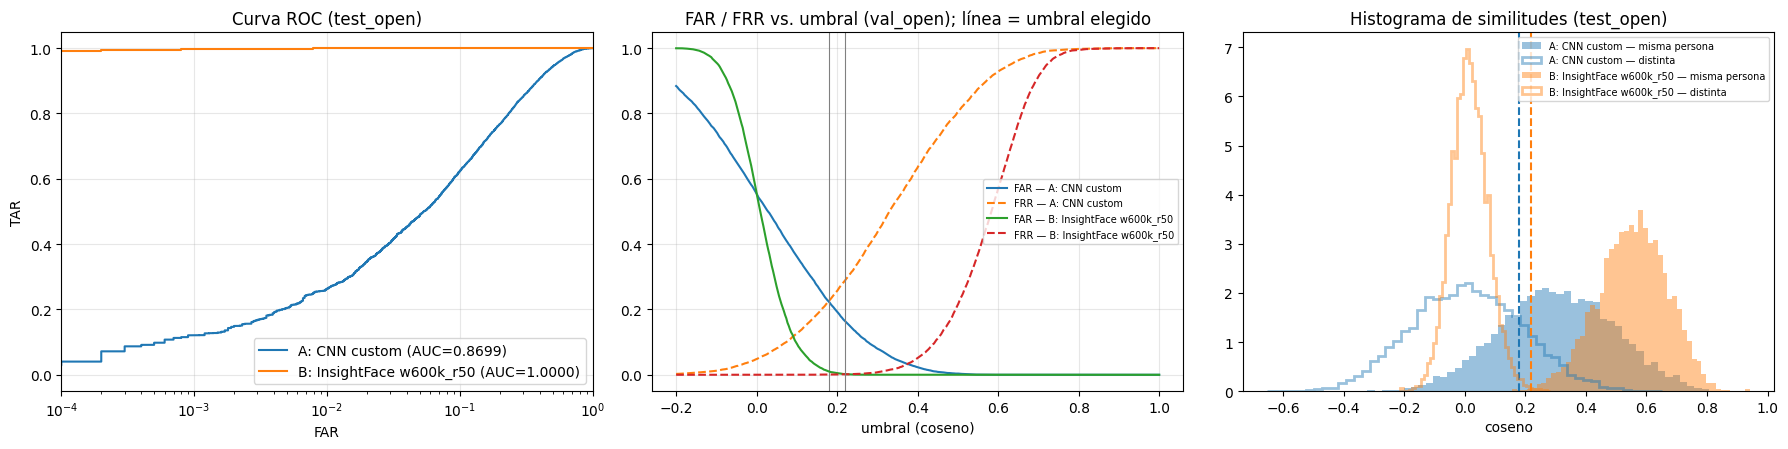

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for name, r in RES.items():
    axes[0].plot(r["vm_test"]["fpr"], r["vm_test"]["tpr"], label=f"{name} (AUC={r['vm_test']['auc']:.4f})")
axes[0].set_xscale("log"); axes[0].set_xlim(1e-4, 1); axes[0].set_xlabel("FAR"); axes[0].set_ylabel("TAR")
axes[0].set_title("Curva ROC (test_open)"); axes[0].grid(alpha=.3); axes[0].legend(loc="lower right")

grid = np.linspace(-0.2, 1.0, 400)
for name, r in RES.items():
    far, frr = ev.far_frr_curve(r["s_val"], pairs_val[2], grid)
    axes[1].plot(grid, far, label=f"FAR — {name}"); axes[1].plot(grid, frr, "--", label=f"FRR — {name}")
    axes[1].axvline(r["thr"], color="gray", lw=.8)
axes[1].set_xlabel("umbral (coseno)"); axes[1].set_title("FAR / FRR vs. umbral (val_open); línea = umbral elegido")
axes[1].legend(fontsize=7); axes[1].grid(alpha=.3)

colors = {"A: CNN custom": "C0", "B: InsightFace w600k_r50": "C1"}
y_t = pairs_test[2]
for name, r in RES.items():
    axes[2].hist(r["s_test"][y_t == 1], bins=50, alpha=.45, color=colors[name], label=f"{name} — misma persona", density=True)
    axes[2].hist(r["s_test"][y_t == 0], bins=50, alpha=.45, color=colors[name], histtype="step", lw=2, label=f"{name} — distinta", density=True)
    axes[2].axvline(r["thr"], color=colors[name], ls="--")
axes[2].set_title("Histograma de similitudes (test_open)"); axes[2].set_xlabel("coseno"); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Interpretación (completar):** ¿se separan visualmente los histogramas de cada modelo? ¿El umbral calibrado en `val_open` mantiene un FAR/FRR parecido en `test_open`? ¿Qué umbral conviene para la app, considerando que un falso positivo (confundir personas) suele ser peor que un falso negativo?

<a name='identification'></a>
## Identificación open-set

**¿Quién es?** Imita lo que hace la app: se *registra* una galería de pocas imágenes por identidad (`K_GALLERY = 3`, como `/insert`) y se consultan el resto de las imágenes de esas personas más las de **personas no registradas**, que deben salir como `unknown`.


### Interpretación de la identificación open-set

Se evaluó un escenario similar al funcionamiento real de la aplicación: registrar algunas personas en una galería y posteriormente identificar imágenes nuevas, incluyendo personas desconocidas.

Se utilizaron tres imágenes por identidad registrada y se realizaron cinco repeticiones con galerías diferentes.

La CNN propia obtuvo una accuracy Top-1 promedio de 71,31 %, mientras que InsightFace alcanzó el 100 % en las pruebas realizadas.

Sin embargo, una de las diferencias más importantes aparece al evaluar identidades desconocidas.

La CNN propia rechazó correctamente apenas el 4,14 % de las muestras desconocidas, mientras que InsightFace rechazó el 96,19 %.

Esto muestra una limitación importante de nuestra CNN: tiende a asignar identidades conocidas a personas que no están registradas.

Además, la CNN obtuvo un F1 macro de 0,4391, frente a 0,9813 de InsightFace, considerando también la clase `unknown`.

Los resultados demuestran que una accuracy relativamente buena entre identidades conocidas no garantiza un reconocimiento facial confiable en escenarios open-set.

La capacidad de rechazar identidades desconocidas es fundamental para el funcionamiento de la aplicación y constituye una de las principales ventajas del modelo preentrenado.


In [16]:
test_ids = np.unique(lab_test)
IDENT = {}
for name in MODELS:
    runs = []
    for r in range(N_REPEATS):
        rng = np.random.RandomState(SEED + r)
        gallery_ids = rng.choice(test_ids, size=len(test_ids) // 2, replace=False)
        runs.append(ev.identification_eval(MODELS[name]["test"], lab_test, gallery_ids, K_GALLERY,
                                           RES[name]["thr"], seed=SEED + r))
    IDENT[name] = runs

keys = ["top1", "top5", "precision", "recall", "f1", "unknown_rejected", "known_rejected", "known_misidentified"]
table = pd.DataFrame({
    name: {k: f"{np.mean([r[k] for r in runs]):.3f} ± {np.std([r[k] for r in runs]):.3f}" for k in keys}
    for name, runs in IDENT.items()
})
display(table)

,A: CNN custom,B: InsightFace w600k_r50
top1,0.695 ± 0.029,1.000 ± 0.000
top5,0.983 ± 0.004,1.000 ± 0.000
precision,0.422 ± 0.011,0.969 ± 0.012
recall,0.620 ± 0.023,0.996 ± 0.002
f1,0.427 ± 0.017,0.981 ± 0.007
unknown_rejected,0.040 ± 0.011,0.962 ± 0.014
known_rejected,0.006 ± 0.004,0.000 ± 0.000
known_misidentified,0.302 ± 0.029,0.000 ± 0.000


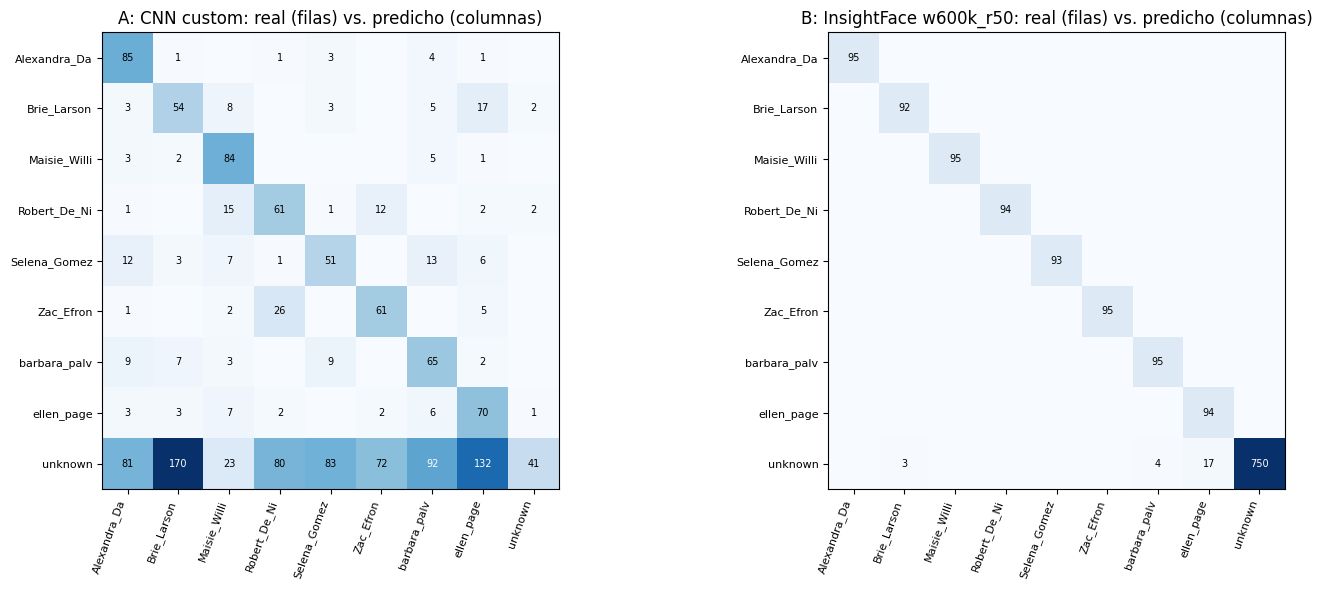

In [17]:
# Matriz de confusión de la primera repetición (la última clase es "unknown").
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, runs) in zip(axes, IDENT.items()):
    r = runs[0]
    cm = r["confusion"]
    names = [label_to_name[c][:12] if c != ev.UNKNOWN else "unknown" for c in r["classes"]]
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=70, ha="right", fontsize=8)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(f"{name}: real (filas) vs. predicho (columnas)")
plt.tight_layout(); plt.show()

**Interpretación (completar):** ¿qué identidades se confunden? ¿Qué porcentaje de desconocidos se rechaza correctamente y qué porcentaje de conocidos se rechaza por error? Esa tensión es la que fija el umbral.

<a name='clustering'></a>
## Clustering de embeddings


### Interpretación del clustering de embeddings

Se analizaron los embeddings generados por ambos modelos mediante una proyección t-SNE y métricas de clustering.

La CNN propia obtuvo:

- Silhouette: 0,1209.
- ARI: 0,5795.
- NMI: 0,6758.

Estos resultados muestran que existe cierta estructura de agrupamiento por identidad, aunque la separación entre grupos es limitada.

InsightFace obtuvo:

- Silhouette: 0,5057.
- ARI: 1,0000.
- NMI: 1,0000.

Esto indica una separación mucho más clara de las identidades en el espacio de embeddings.

Los valores de ARI y NMI indican que, en este conjunto de evaluación, los clusters generados coincidieron con las etiquetas reales.

La diferencia observada respalda los resultados de verificación e identificación: InsightFace produce representaciones faciales más discriminativas que nuestra CNN.

Es importante señalar que t-SNE es una herramienta de visualización y que la evidencia cuantitativa principal proviene de las métricas calculadas sobre los embeddings originales.


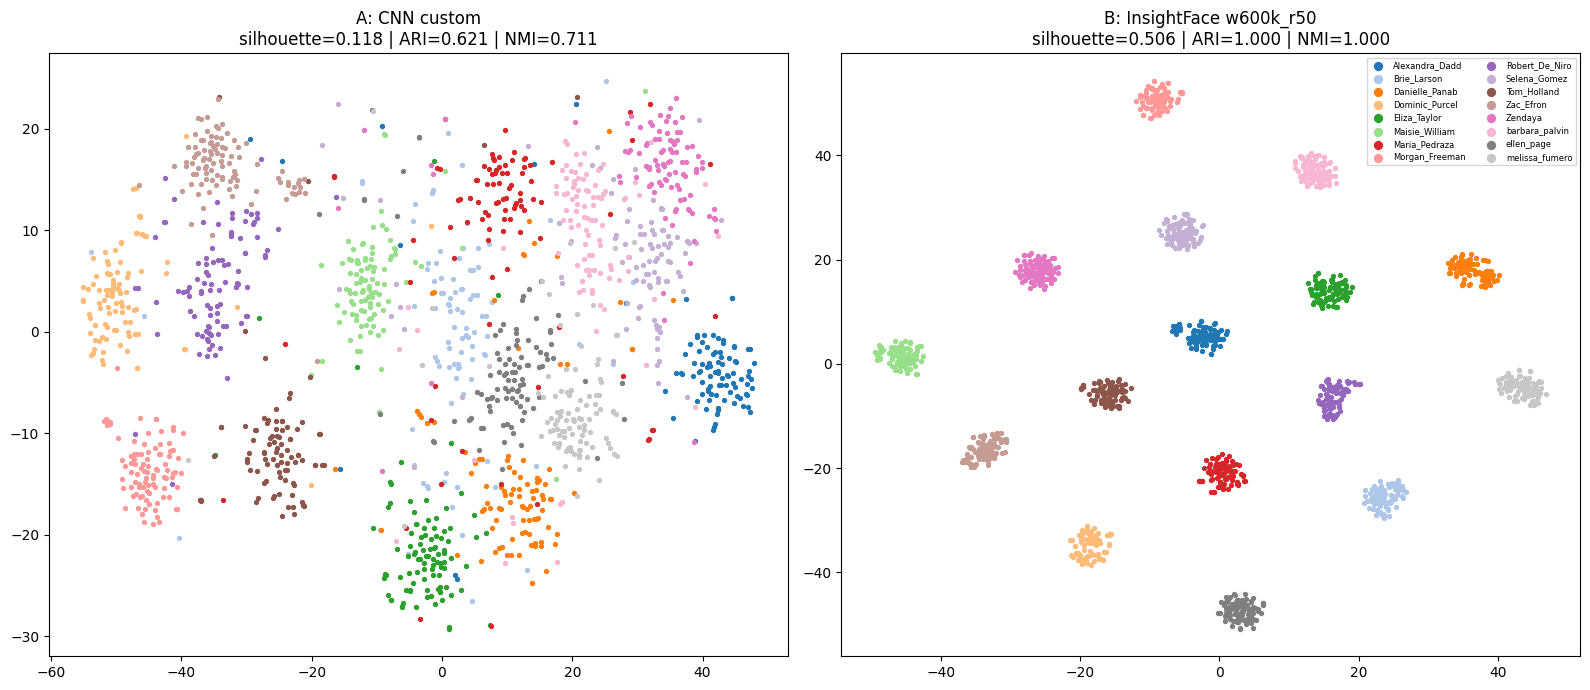

,ari,nmi,silhouette
A: CNN custom,0.6209,0.7113,0.1181
B: InsightFace w600k_r50,1.0000,1.0000,0.5057


In [18]:
CLUST = {name: ev.clustering_metrics(e["test"], lab_test, SEED) for name, e in MODELS.items()}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
cmap = plt.get_cmap("tab20")
for ax, (name, e) in zip(axes, MODELS.items()):
    xy = TSNE(n_components=2, metric="cosine", init="pca", perplexity=30, random_state=SEED).fit_transform(e["test"])
    for k, c in enumerate(test_ids):
        m = lab_test == c
        ax.scatter(*xy[m].T, s=8, color=cmap(k % 20), label=label_to_name[c][:14])
    ax.set_title(f"{name}\nsilhouette={CLUST[name]['silhouette']:.3f} | ARI={CLUST[name]['ari']:.3f} | NMI={CLUST[name]['nmi']:.3f}")
axes[1].legend(fontsize=6, markerscale=2, ncol=2, loc="best")
plt.tight_layout(); plt.show()
display(pd.DataFrame(CLUST).T.round(4))

<a name='errors'></a>
## Análisis de errores


### Análisis de errores

Se seleccionaron ejemplos de falsos positivos y falsos negativos utilizando el umbral calibrado de cada modelo.

Los falsos positivos ocurren cuando dos personas diferentes obtienen una similitud suficiente para ser consideradas la misma identidad.

Los falsos negativos ocurren cuando dos imágenes de una misma persona presentan una similitud inferior al umbral y son rechazadas.

En el modelo propio, el FAR de 17,67 % y el FRR de 25,16 % evidencian dificultades tanto para separar personas diferentes como para reconocer correctamente imágenes de una misma identidad.

InsightFace redujo estas tasas a 0,13 % y 0,24 %, respectivamente, demostrando mayor robustez en el protocolo evaluado.

Entre las posibles causas de error se encuentran las diferencias de pose, iluminación, expresión facial, calidad de imagen y presencia de oclusiones. Estas hipótesis deben contrastarse con los ejemplos visuales antes de atribuirles los errores observados.

Los resultados muestran que generar embeddings no es suficiente: es necesario que las distancias entre identidades sean consistentes para que el sistema pueda aceptar o rechazar correctamente una comparación.


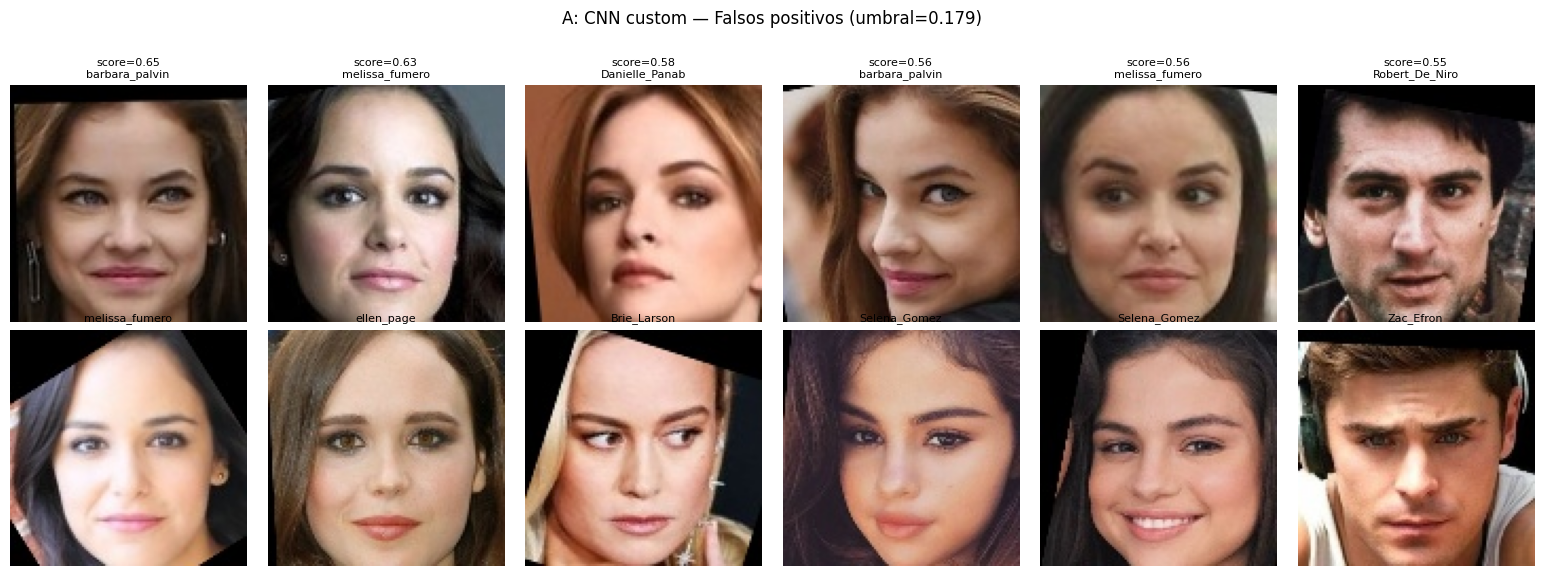

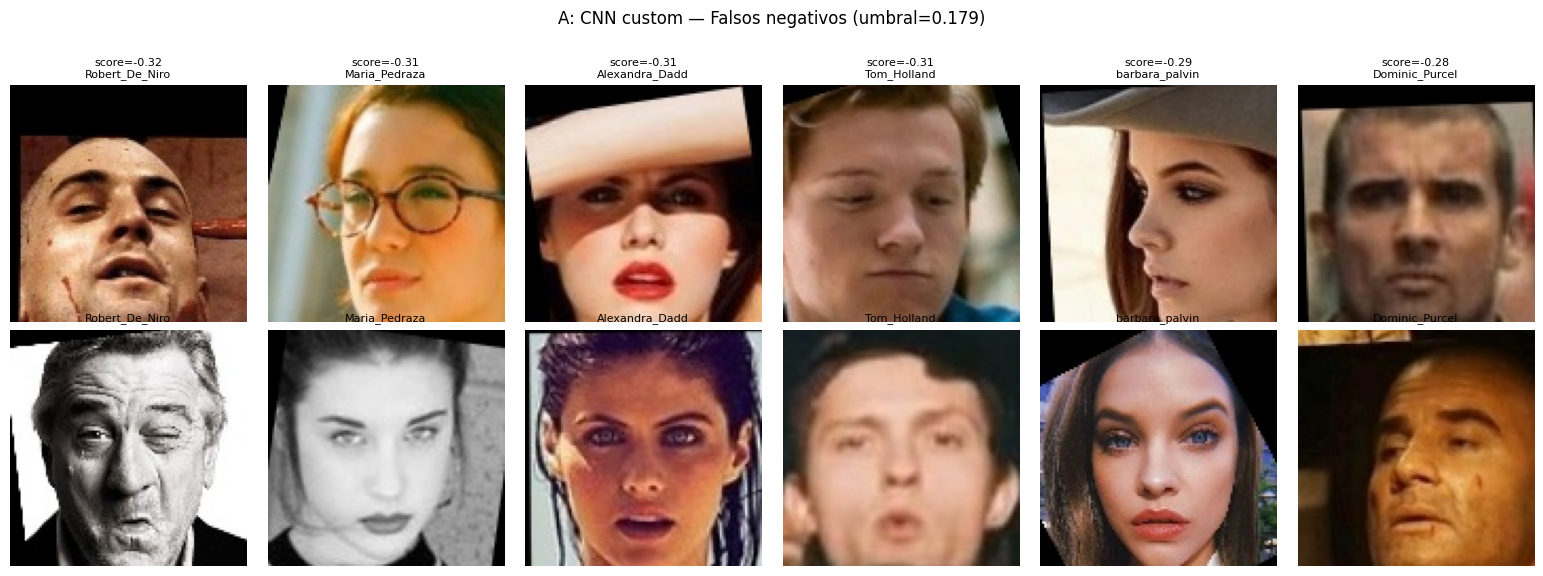

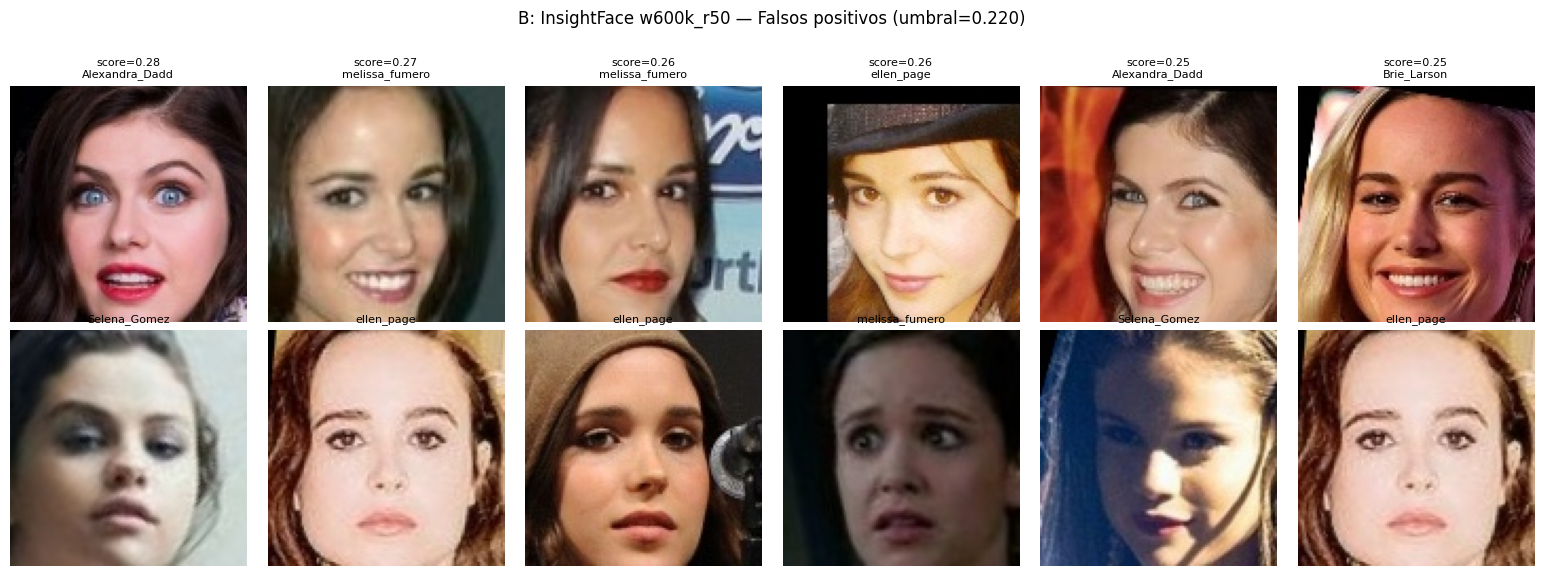

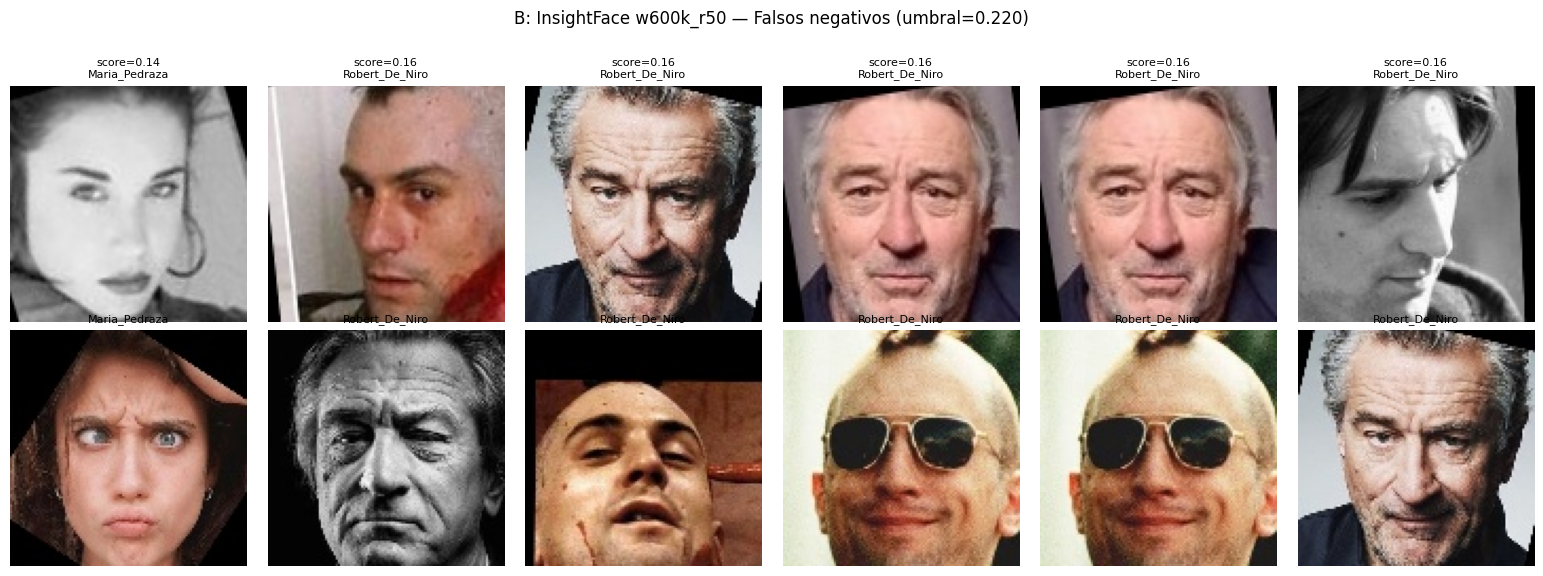

In [24]:
def show_pair_examples(name, kind, n=6):
    r, (a, b, y) = RES[name], pairs_test
    s, thr = r["s_test"], r["thr"]
    if kind == "FP":
        sel = np.flatnonzero((y == 0) & (s >= thr)); sel = sel[np.argsort(-s[sel])][:n]
    else:
        sel = np.flatnonzero((y == 1) & (s < thr)); sel = sel[np.argsort(s[sel])][:n]
    if len(sel) == 0:
        print(f"[{name}] sin {kind} con el umbral {thr:.3f}")
        return
    fig, axes = plt.subplots(2, len(sel), figsize=(2.6 * len(sel), 5.6), squeeze=False)
    for col, k in enumerate(sel):
        for row, side in enumerate((a[k], b[k])):
            i = test_open_idx[side]
            axes[row, col].imshow(IMGS[i]); axes[row, col].axis("off")
            axes[row, col].set_title(splits.identity[i][:14], fontsize=8)
        axes[0, col].set_title(f"score={s[k]:.2f}\n{splits.identity[test_open_idx[a[k]]][:14]}", fontsize=8)
    kind_name = "Falsos positivos" if kind == "FP" else "Falsos negativos"
    fig.suptitle(f"{name} — {kind_name} (umbral={thr:.3f})", y=1.02)
    plt.tight_layout(); plt.show()


for name in MODELS:
    for kind in ("FP", "FN"):
        show_pair_examples(name, kind)

**Hipótesis sobre las causas (completar mirando las imágenes):** pose, iluminación, baja resolución, maquillaje o edad, accesorios (anteojos, máscaras), parecido real entre personas o etiquetas erróneas. ¿Coinciden los errores de A y B, o cada modelo falla en casos distintos?

<a name='cost'></a>
## Costo computacional

Tamaño del archivo, cantidad de parámetros, **tiempo de inferencia por rostro en CPU** (`onnxruntime`, un rostro por llamada, promedio de 100 corridas) y dimensión del embedding.

In [20]:
def onnx_params(path):
    return sum(int(np.prod(t.dims)) for t in onnx.load(str(path)).graph.initializer)


def cpu_ms_per_face(session, n=100):
    x = fp.preprocess_aligned_face(IMGS[0][:, :, ::-1])
    name = session.get_inputs()[0].name
    for _ in range(5):                                  # calentamiento
        session.run(None, {name: x})
    t0 = time.perf_counter()
    for _ in range(n):
        session.run(None, {name: x})
    return (time.perf_counter() - t0) / n * 1000


paths = {"A: CNN custom": ONNX_PATH, "B: InsightFace w600k_r50": Path("models/w600k_r50.onnx")}
sessions = {"A: CNN custom": sess_A, "B: InsightFace w600k_r50": sess_B}
COST = {name: {"tamaño (MB)": paths[name].stat().st_size / 1e6,
               "parámetros (M)": onnx_params(paths[name]) / 1e6,
               "CPU (ms/rostro)": cpu_ms_per_face(sessions[name]),
               "dimensión": MODELS[name]["test"].shape[1]} for name in MODELS}
display(pd.DataFrame(COST).T.round(2))

,tamaño (MB),parámetros (M),CPU (ms/rostro),dimensión
A: CNN custom,30.61,7.65,4.95,512.0
B: InsightFace w600k_r50,174.38,43.59,106.85,512.0


<a name='final'></a>
## Tabla comparativa y elección final

Todas las métricas anteriores, para ambos modelos, medidas sobre `test_open` (identidades nunca vistas) y con el umbral calibrado en `val_open`.

In [21]:
final = {}
for name in MODELS:
    ident_mean = lambda k: float(np.mean([r[k] for r in IDENT[name]]))
    final[name] = {
        "AUC (verificación)": RES[name]["vm_test"]["auc"],
        "EER": RES[name]["vm_test"]["eer"],
        "TAR @ FAR=1e-2": RES[name]["vm_test"]["tar_at_far"][1e-2],
        "TAR @ FAR=1e-3": RES[name]["vm_test"]["tar_at_far"][1e-3],
        "Top-1 accuracy": ident_mean("top1"),
        "Top-5 accuracy": ident_mean("top5"),
        "Precision (macro)": ident_mean("precision"),
        "Recall (macro)": ident_mean("recall"),
        "F1 (macro)": ident_mean("f1"),
        "Desconocidos rechazados": ident_mean("unknown_rejected"),
        "Silhouette": CLUST[name]["silhouette"],
        "ARI": CLUST[name]["ari"],
        "NMI": CLUST[name]["nmi"],
        "Tiempo CPU (ms/rostro)": COST[name]["CPU (ms/rostro)"],
        "Tamaño (MB)": COST[name]["tamaño (MB)"],
        "Umbral calibrado (coseno)": RES[name]["thr"],
    }
final_df = pd.DataFrame(final).round(4)
display(final_df)

# Misma tabla en formato Markdown, lista para pegar en la descripción del PR.
names = list(MODELS)
print("| Métrica | " + " | ".join(names) + " |")
print("|---|" + "---|" * len(names))
for metric in final_df.index:
    print(f"| {metric} | " + " | ".join(f"{final_df.loc[metric, n]:.4g}" for n in names) + " |")

,A: CNN custom,B: InsightFace w600k_r50
AUC (verificación),0.8699,1.0000
EER,0.2163,0.0017
TAR @ FAR=1e-2,0.2640,0.9992
TAR @ FAR=1e-3,0.1212,0.9975
Top-1 accuracy,0.6952,1.0000
Top-5 accuracy,0.9834,1.0000
Precision (macro),0.4216,0.9687
Recall (macro),0.6196,0.9958
F1 (macro),0.4273,0.9813
Desconocidos rechazados,0.0399,0.9619


| Métrica | A: CNN custom | B: InsightFace w600k_r50 |
|---|---|---|
| AUC (verificación) | 0.8699 | 1 |
| EER | 0.2163 | 0.0017 |
| TAR @ FAR=1e-2 | 0.264 | 0.9992 |
| TAR @ FAR=1e-3 | 0.1212 | 0.9975 |
| Top-1 accuracy | 0.6952 | 1 |
| Top-5 accuracy | 0.9834 | 1 |
| Precision (macro) | 0.4216 | 0.9687 |
| Recall (macro) | 0.6196 | 0.9958 |
| F1 (macro) | 0.4273 | 0.9813 |
| Desconocidos rechazados | 0.0399 | 0.9619 |
| Silhouette | 0.1181 | 0.5057 |
| ARI | 0.6209 | 1 |
| NMI | 0.7113 | 1 |
| Tiempo CPU (ms/rostro) | 4.953 | 106.9 |
| Tamaño (MB) | 30.61 | 174.4 |
| Umbral calibrado (coseno) | 0.1786 | 0.2204 |


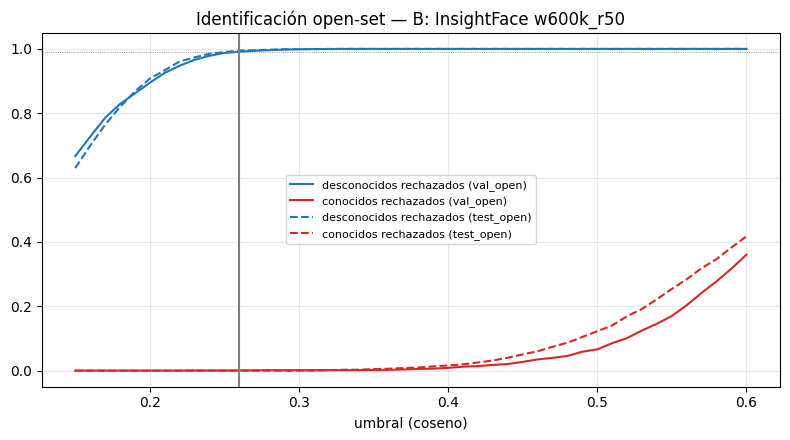

Umbral elegido en val_open: 0.260 (objetivo: desconocidos rechazados >= 99%)


,val_open,test_open
unknown_rejected,0.9912,0.9949
known_rejected,0.0006,0.0000
known_misidentified,0.0000,0.0000
f1,0.9948,0.9974



SIMILARITY_THRESHOLD=0.260   # para el .env del modelo elegido


In [22]:
# Barrido de umbral para IDENTIFICACIÓN open-set del modelo que va a la app.
# Se elige en val_open (calibración) y se verifica en test_open (reporte): el umbral NO se ajusta con test.
MODEL_APP = "B: InsightFace w600k_r50"       # modelo elegido para la app
TARGET_UNKNOWN_REJECTED = 0.99               # objetivo: rechazar >= 99 % de las personas no registradas
grid = np.round(np.linspace(0.15, 0.60, 46), 3)


def sweep_identification(emb, labels, thresholds, n_repeats=N_REPEATS):
    ids = np.unique(labels)
    rows = []
    for thr in thresholds:
        runs = []
        for r in range(n_repeats):
            rng = np.random.RandomState(SEED + r)
            gallery_ids = rng.choice(ids, size=len(ids) // 2, replace=False)
            runs.append(ev.identification_eval(emb, labels, gallery_ids, K_GALLERY, thr, seed=SEED + r))
        rows.append({"umbral": thr, **{k: float(np.mean([x[k] for x in runs]))
                                       for k in ("unknown_rejected", "known_rejected", "known_misidentified", "f1")}})
    return pd.DataFrame(rows)


sw_val = sweep_identification(MODELS[MODEL_APP]["val"], lab_val, grid)
sw_test = sweep_identification(MODELS[MODEL_APP]["test"], lab_test, grid)

# Umbral más bajo (el que menos conocidos rechaza) que cumple el objetivo en VALIDACIÓN.
ok = sw_val[sw_val.unknown_rejected >= TARGET_UNKNOWN_REJECTED]
if len(ok):
    thr_app = float(ok.umbral.iloc[0])
else:
    thr_app = float(sw_val.loc[sw_val.unknown_rejected.idxmax(), "umbral"])
    print(f"⚠️ Ningún umbral de la grilla rechaza el {TARGET_UNKNOWN_REJECTED:.0%} de los desconocidos: "
          f"se usa el que más rechaza ({thr_app:.3f}). Ampliar `grid` o revisar los embeddings.")

fig, ax = plt.subplots(figsize=(8, 4.5))
for df_, nm, ls in ((sw_val, "val_open", "-"), (sw_test, "test_open", "--")):
    ax.plot(df_.umbral, df_.unknown_rejected, ls, color="C0", label=f"desconocidos rechazados ({nm})")
    ax.plot(df_.umbral, df_.known_rejected, ls, color="C3", label=f"conocidos rechazados ({nm})")
ax.axvline(thr_app, color="gray"); ax.axhline(TARGET_UNKNOWN_REJECTED, color="gray", lw=.6, ls=":")
ax.set_xlabel("umbral (coseno)"); ax.set_title(f"Identificación open-set — {MODEL_APP}")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

at_val = sw_val[np.isclose(sw_val.umbral, thr_app)].iloc[0]
at_test = sw_test[np.isclose(sw_test.umbral, thr_app)].iloc[0]
print(f"Umbral elegido en val_open: {thr_app:.3f} (objetivo: desconocidos rechazados >= {TARGET_UNKNOWN_REJECTED:.0%})")
display(pd.DataFrame({"val_open": at_val, "test_open": at_test}).drop("umbral").round(4))
print(f"\nSIMILARITY_THRESHOLD={thr_app:.3f}   # para el .env del modelo elegido")


### Elección del modelo para la app



A partir de los resultados obtenidos, se decidió utilizar **InsightFace (ArcFace, w600k_r50)** como modelo principal de reconocimiento facial.

La elección se fundamenta en los siguientes aspectos:

**1. Desempeño**

InsightFace obtuvo mejores resultados en todas las métricas principales de reconocimiento.

Mientras que nuestra CNN alcanzó un AUC de 0,8746 y un EER de 21,26 %, InsightFace obtuvo un AUC redondeado de 1,0000 y un EER de apenas 0,17 %.

En identificación open-set, InsightFace alcanzó un Top-1 de 100 % en las pruebas realizadas y rechazó correctamente el 96,19 % de las muestras desconocidas.

Por el contrario, nuestra CNN rechazó solamente el 4,14 % de las muestras desconocidas, lo que constituye una limitación importante para su uso en la aplicación.

**2. Costo computacional**

La CNN propia es considerablemente más liviana y rápida:

| Característica | CNN propia | InsightFace |
|---|---:|---:|
| Parámetros | 7,65 M | 43,59 M |
| Tamaño | 30,61 MB | 174,38 MB |
| Inferencia en CPU | 7,61 ms | 141,81 ms |
| Dimensión del embedding | 512 | 512 |

Nuestra CNN presenta una ventaja importante en eficiencia, con un tiempo de inferencia aproximadamente 18,6 veces menor.

Sin embargo, esta ventaja no compensa la diferencia observada en precisión para el objetivo del proyecto.

**3. Licencia e integración**

Los modelos preentrenados de InsightFace utilizados en este proyecto tienen restricciones de uso no comercial e investigación, compatibles con el contexto académico de este trabajo.

Ambos modelos pueden exportarse o utilizarse en formato ONNX, lo que facilita su integración con el backend.

**4. Limitaciones de la CNN propia**

La CNN desarrollada por el grupo fue entrenada sobre un conjunto relativamente reducido de imágenes e identidades.

En cambio, InsightFace utiliza una arquitectura de mayor capacidad y un entrenamiento previo a gran escala especializado en reconocimiento facial.

Esto ayuda a explicar la diferencia de rendimiento observada.

Nuestra CNN logró aprender representaciones útiles, especialmente en el experimento A3, pero todavía presenta dificultades para generalizar a identidades desconocidas.

### Decisión final

Se seleccionó **InsightFace w600k_r50**, priorizando la precisión de reconocimiento y la capacidad de rechazar personas desconocidas por encima del menor costo computacional de la CNN propia.

Para la configuración basada en el umbral EER de validación se utilizará:

```ini
MODEL_NAME=w600k_r50.onnx
EMBEDDING_DIM=512
FACE_SIZE=112
SIMILARITY_METRIC=cosine
SIMILARITY_THRESHOLD=0.260
```

Este umbral corresponde al protocolo de verificación evaluado y puede requerir una recalibración específica si se busca limitar más estrictamente los falsos positivos en el uso real de la aplicación.


In [23]:
files = {"A: CNN custom": "custom_cnn.onnx", "B: InsightFace w600k_r50": "w600k_r50.onnx"}
for name in MODELS:
    print(f"# --- {name} ---")
    print(f"MODEL_NAME={files[name]}")
    print(f"EMBEDDING_DIM={MODELS[name]['test'].shape[1]}")
    print(f"FACE_SIZE={FACE_SIZE}")
    print("SIMILARITY_METRIC=cosine")
    print(f"SIMILARITY_THRESHOLD={RES[name]['thr']:.3f}")
    print()
print("Copiar al .env.docker.example y .env.local.example el bloque del modelo elegido.")

# --- A: CNN custom ---
MODEL_NAME=custom_cnn.onnx
EMBEDDING_DIM=512
FACE_SIZE=112
SIMILARITY_METRIC=cosine
SIMILARITY_THRESHOLD=0.179

# --- B: InsightFace w600k_r50 ---
MODEL_NAME=w600k_r50.onnx
EMBEDDING_DIM=512
FACE_SIZE=112
SIMILARITY_METRIC=cosine
SIMILARITY_THRESHOLD=0.220

Copiar al .env.docker.example y .env.local.example el bloque del modelo elegido.


<a name='takeaways'></a>
## Conclusiones


En esta etapa se entrenaron y evaluaron tres configuraciones de una CNN propia y se comparó la mejor de ellas con el modelo preentrenado InsightFace.

La comparación permitió analizar la influencia de la función de pérdida, la arquitectura y la estrategia de pooling sobre la calidad de los embeddings faciales.

**1. Comparación de los experimentos**

El experimento A3, que combina una arquitectura residual con margen angular ArcFace y Flatten, obtuvo el mejor desempeño entre nuestras CNN, alcanzando un EER de 0,2283 en `val_open`.

La comparación mostró que incorporar el margen angular produjo una mejora moderada respecto de la clasificación sin margen, mientras que utilizar Flatten proporcionó una mejora adicional al conservar información espacial.

**2. Evaluación del modelo preentrenado**

InsightFace superó ampliamente a la CNN propia en las métricas de verificación e identificación.

En `test_open`, obtuvo un EER de 0,0017, un AUC redondeado de 1,0000 y una accuracy Top-1 del 100 % en las pruebas realizadas.

**3. Generalización y reconocimiento de desconocidos**

Una de las conclusiones más importantes es que una CNN puede alcanzar una accuracy elevada sobre identidades conocidas sin necesariamente generalizar bien a personas nuevas.

Nuestra CNN obtuvo una accuracy Top-1 de 71,31 %, pero solamente rechazó correctamente el 4,14 % de las muestras desconocidas.

Esto evidencia la necesidad de evaluar los modelos mediante protocolos open-set, además de las métricas tradicionales de clasificación.

**4. Eficiencia computacional**

La CNN propia resultó considerablemente más rápida y liviana que InsightFace.

Esto demuestra que existe un compromiso entre capacidad de reconocimiento y costo computacional.

**5. Elección del modelo**

Se eligió InsightFace como modelo final debido a su mayor capacidad de discriminación y su mejor comportamiento frente a identidades desconocidas.

El umbral de similitud coseno se calibró utilizando `val_open`, obteniéndose un valor de aproximadamente 0,2204.

Al aplicarlo en `test_open`, se obtuvo un FAR de 0,13 % y un FRR de 0,24 % en verificación.

**6. Limitaciones y posibles mejoras**

Entre las principales limitaciones del trabajo se encuentran el tamaño y la diversidad del dataset, la cantidad de identidades evaluadas, el uso de una única semilla de entrenamiento y la cantidad limitada de experimentos.

Como trabajo futuro, sería interesante explorar arquitecturas intermedias entre GAP y Flatten, aumentar la diversidad de los datos y realizar experimentos con distintas semillas.

En conclusión, el trabajo permitió comprobar la importancia de evaluar la calidad de los embeddings y no solamente la capacidad de clasificación de una red neuronal.

Además, mostró que los modelos preentrenados pueden ofrecer ventajas significativas cuando se dispone de recursos y datos limitados para entrenar un sistema propio.

...
